
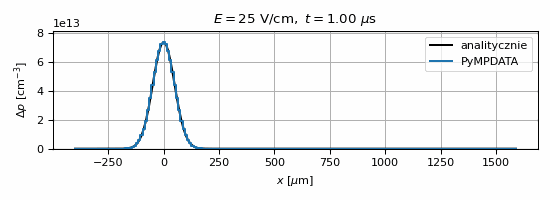

HTML(value="<a href='.\\tmp41hn21ln.gif' target='_blank'>.\\tmp41hn21ln.gif</a><br>")

In [9]:
%config InlineBackend.figure_format = 'svg'
import os, sys, subprocess; os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'open-atmos-jupyter-utils', 'PyMPDATA'], stdout=subprocess.DEVNULL)
import numpy as np; from matplotlib import pyplot as plt
from open_atmos_jupyter_utils import show_anim, show_plot
from PyMPDATA import (Options, ScalarField, Solver, Stepper,
                      VectorField, boundary_conditions)
plt.rcParams.update({'font.size': 8})
N, D, mu_p, tau, t0, t1, E = 1e12, 12.0, 480.0, 10e-6, 1e-6, 7e-6, 25.0
opts = Options(n_iters=3, non_zero_mu_coeff=True, nonoscillatory=True)

def analytical(x, t):
    return N / np.sqrt(4*np.pi*D*t) * np.exp(-x**2 / (4*D*t) - t / tau)

def solve(nx, nt, outfreq):
    x, dx = np.linspace(-0.04, 0.16, nx, endpoint=False, retstep=True)
    dt = (t1 - t0) / nt; C = mu_p * E * dt / dx; mu_num = D * dt / dx**2
    assert abs(C) <= 1.0 and mu_num <= 0.5
    bcs = (boundary_conditions.Periodic(),)
    psi0 = analytical(x, t0)
    sol = Solver(Stepper(options=opts, n_dims=1),
                 ScalarField(psi0.copy(), opts.n_halo, bcs),
                 VectorField((np.full(nx + 1, C),), opts.n_halo, bcs))
    hist, steps = [psi0.copy()], [0]
    for it in range(1, nt + 1):
        psi = sol.advectee.get()
        psi[:] -= 0.5 * (dt / tau) * psi
        sol.advance(1, mu_coeff=(mu_num,))
        psi[:] -= 0.5 * (dt / tau) * psi
        if it % outfreq == 0: hist.append(psi.copy()); steps.append(it)
    return x, dx, dt, hist, steps

x, dx, dt, hist, steps = solve(nx=200, nt=500, outfreq=50)
assert np.all(hist[-1] >= 0) and np.isclose(
    np.sum(hist[-1]) * dx, N * np.exp(-t1 / tau), rtol=1e-2)

def plot_frame(k):
    tc = t0 + steps[k] * dt; fig, ax = plt.subplots(figsize=(5.5, 2.0))
    ax.plot(x*1e4, analytical(x - mu_p*E*(tc - t0), tc), 'k-', label='analitycznie')
    ax.step(x*1e4, hist[k], where='mid', label='PyMPDATA')
    ax.set(xlabel=r'$x\ [\mu\mathrm{m}]$', ylabel=r'$\Delta p\ [\mathrm{cm}^{-3}]$',
           ylim=(0, np.max(hist[0])*1.1),
           title=rf'$E = {E:.0f}\ \mathrm{{V/cm}},\ t = {tc*1e6:.2f}\ \mu\mathrm{{s}}$')
    ax.grid(True); ax.legend(); plt.tight_layout(); return fig
show_anim(plot_frame, range(len(hist)))


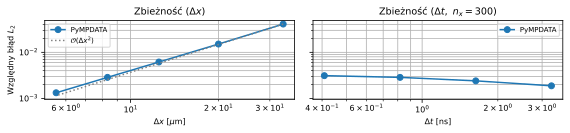

In [10]:
def rel_err(nx, nt):
    xg, _, _, h, _ = solve(nx, nt, outfreq=nt)
    ref = analytical(xg - mu_p * E * (t1 - t0), t1)
    return np.linalg.norm(h[-1] - ref) / np.linalg.norm(ref)

ncs = [60, 100, 160, 240, 360]; dxs = [0.2 / nc for nc in ncs]
nts_x = [int(np.ceil((2*mu_p*E/d + 10*D/d**2) * (t1 - t0))) for d in dxs]
err_x = [rel_err(nc, n) for nc, n in zip(ncs, nts_x)]

dxf = 0.2 / 300; nt0 = int(np.ceil((2*mu_p*E/dxf + 10*D/dxf**2) * (t1 - t0)))
nts_t = [nt0 * m for m in (1, 2, 4, 8)]
err_t = [rel_err(300, n) for n in nts_t]
dxs_um, dts_ns = np.array(dxs) * 1e4, (t1 - t0) / np.array(nts_t) * 1e9

fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.0, 2.0), sharey=True)
a1.loglog(dxs_um, err_x, 'o-', label='PyMPDATA')
a1.loglog(dxs_um, err_x[0]*(dxs_um/dxs_um[0])**2, ':', c='gray', label=r'$\mathcal{O}(\Delta x^2)$')
a1.set(xlabel=r'$\Delta x\ [\mu\mathrm{m}]$', ylabel=r'Względny błąd $L_2$', title=r'Zbieżność ($\Delta x$)')
a2.loglog(dts_ns, err_t, 'o-', label='PyMPDATA')
a2.set(xlabel=r'$\Delta t\ [\mathrm{ns}]$', title=r'Zbieżność ($\Delta t,\ n_x=300$)')
for a in (a1, a2): a.grid(True, which='both'); a.legend(fontsize=7)
plt.tight_layout(); show_plot('zbieznosc')
